# Stage 2 — Image Validation & Preprocessing

This notebook contains the original cells for image-dimension inspection, image validation, 224×224 resizing with padding, processed-image validation, and preprocessing reports.

**Original outputs are preserved. Cells have not been executed or modified.**

In [45]:
!pip install -q opencv-python-headless tqdm

import os
import cv2
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
IMG_SIZE = 224

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [46]:
INPUT_CSV = (
    "/kaggle/working/DR_Data_Audit/"
    "proposed_clean_dataset.csv"
)

OUTPUT_DIR = "/kaggle/working/DR_Prepared"

IMAGE_DIR = os.path.join(
    OUTPUT_DIR,
    "images"
)

os.makedirs(IMAGE_DIR, exist_ok=True)

print("Input CSV:", INPUT_CSV)
print("Output directory:", OUTPUT_DIR)
print("Image size:", IMG_SIZE, "x", IMG_SIZE)

Input CSV: /kaggle/working/DR_Data_Audit/proposed_clean_dataset.csv
Output directory: /kaggle/working/DR_Prepared
Image size: 224 x 224


In [47]:
if not os.path.exists(INPUT_CSV):
    raise FileNotFoundError(INPUT_CSV)

df = pd.read_csv(INPUT_CSV)

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

required_columns = ["image_path", "level"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing column: {col}")

df = df[required_columns].copy()

df["level"] = pd.to_numeric(
    df["level"],
    errors="coerce"
)

df = df.dropna(
    subset=["image_path", "level"]
)

df["level"] = df["level"].astype(int)

if not df["level"].isin([0, 1, 2, 3, 4]).all():
    raise ValueError("Invalid DR labels detected.")

print("\nTotal images:", len(df))

print("\nClass distribution:")
display(df["level"].value_counts().sort_index())

Original shape: (35126, 9)
Columns: ['image', 'level', 'image_key', 'image_path', 'quality_flag', 'exact_duplicate', 'cross_class_exact_duplicate', 'near_duplicate_flag', 'remove_candidate']

Total images: 35126

Class distribution:


level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64

In [48]:
dimension_records = []
dimension_errors = []

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Checking dimensions"
):

    path = row["image_path"]

    img = cv2.imread(path)

    if img is None:
        dimension_errors.append(path)
        continue

    h, w = img.shape[:2]

    dimension_records.append({
        "image_path": path,
        "level": row["level"],
        "width": w,
        "height": h,
        "aspect_ratio": w / h
    })

dimensions_df = pd.DataFrame(dimension_records)

print("Readable images:", len(dimensions_df))
print("Unreadable images:", len(dimension_errors))

display(dimensions_df.head())

Checking dimensions:   0%|          | 0/35126 [00:00<?, ?it/s]

Readable images: 35126
Unreadable images: 0


,image_path,level,width,height,aspect_ratio
0,/kaggle/input/datasets/sovitrath/diabetic-reti...,0,224,224,1.0
1,/kaggle/input/datasets/sovitrath/diabetic-reti...,0,224,224,1.0
2,/kaggle/input/datasets/sovitrath/diabetic-reti...,0,224,224,1.0
3,/kaggle/input/datasets/sovitrath/diabetic-reti...,0,224,224,1.0
4,/kaggle/input/datasets/sovitrath/diabetic-reti...,1,224,224,1.0


In [49]:
print("Width statistics:")
display(dimensions_df["width"].describe())

print("\nHeight statistics:")
display(dimensions_df["height"].describe())

print("\nAspect Ratio statistics:")
display(dimensions_df["aspect_ratio"].describe())

Width statistics:


count    35126.0
mean       224.0
std          0.0
min        224.0
25%        224.0
50%        224.0
75%        224.0
max        224.0
Name: width, dtype: float64


Height statistics:


count    35126.0
mean       224.0
std          0.0
min        224.0
25%        224.0
50%        224.0
75%        224.0
max        224.0
Name: height, dtype: float64


Aspect Ratio statistics:


count    35126.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: aspect_ratio, dtype: float64

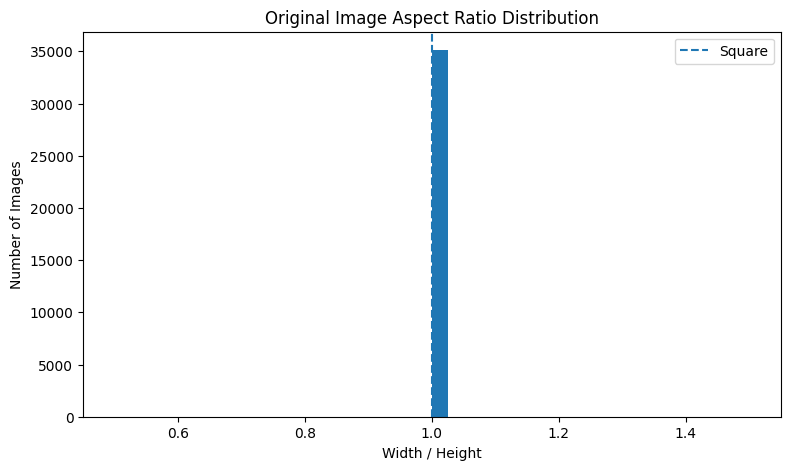

In [50]:
plt.figure(figsize=(9, 5))

plt.hist(
    dimensions_df["aspect_ratio"],
    bins=40
)

plt.axvline(
    1,
    linestyle="--",
    label="Square"
)

plt.title("Original Image Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.ylabel("Number of Images")

plt.legend()
plt.show()

In [51]:
valid_records = []
invalid_records = []

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Validating images"
):

    path = row["image_path"]
    label = row["level"]

    if not os.path.isfile(path):
        invalid_records.append({
            "image_path": path,
            "reason": "File not found"
        })
        continue

    img = cv2.imread(path)

    if img is None:
        invalid_records.append({
            "image_path": path,
            "reason": "Cannot read image"
        })
        continue

    if img.ndim != 3 or img.shape[2] != 3:
        invalid_records.append({
            "image_path": path,
            "reason": "Invalid channels"
        })
        continue

    if img.shape[0] < 10 or img.shape[1] < 10:
        invalid_records.append({
            "image_path": path,
            "reason": "Invalid dimensions"
        })
        continue

    valid_records.append({
        "image_path": path,
        "level": label
    })

valid_df = pd.DataFrame(valid_records)
invalid_df = pd.DataFrame(invalid_records)

print("Valid images:", len(valid_df))
print("Invalid images:", len(invalid_df))

if len(invalid_df) > 0:
    display(invalid_df.head(20))

Validating images:   0%|          | 0/35126 [00:00<?, ?it/s]

Valid images: 35126
Invalid images: 0


In [53]:
invalid_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "invalid_original_images.csv"
    ),
    index=False
)

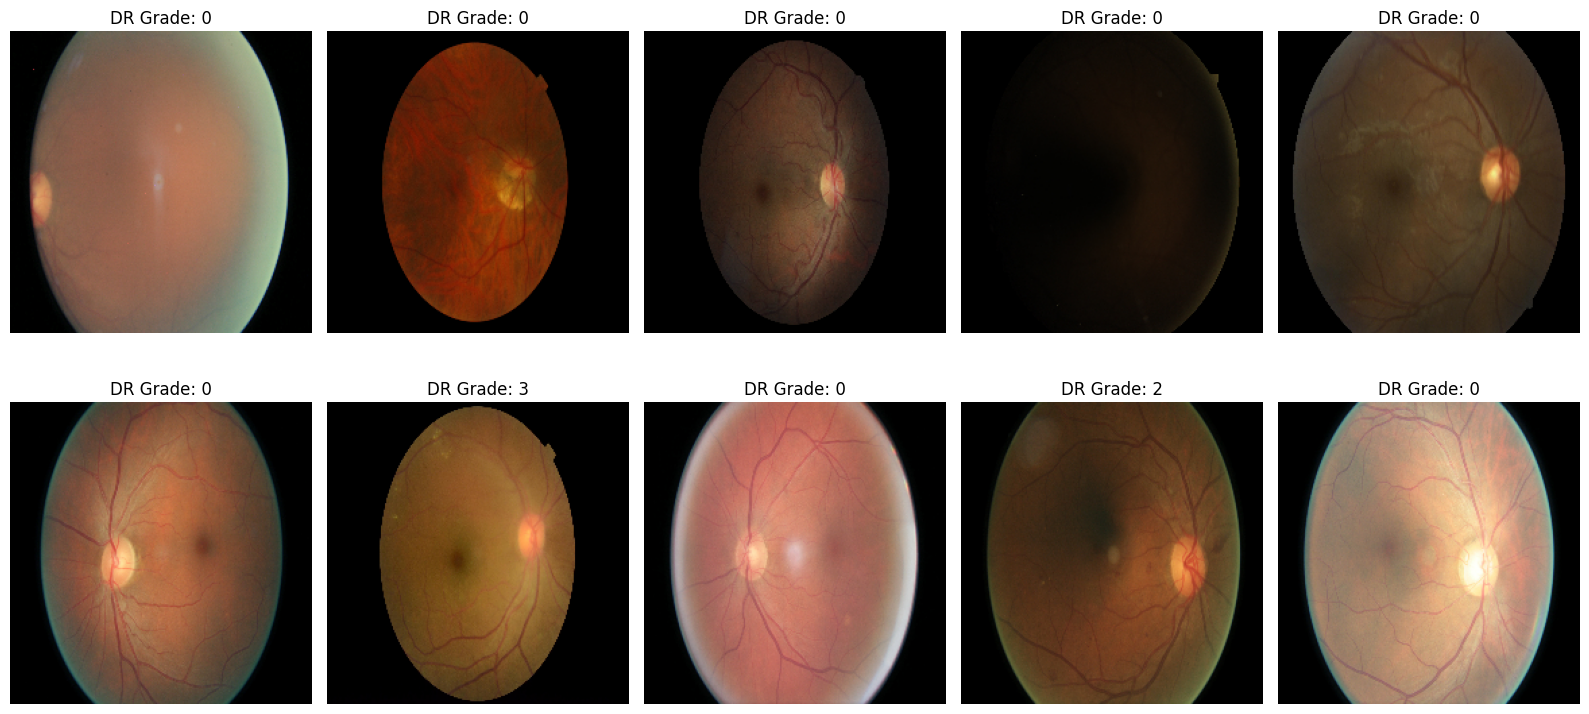

In [54]:
sample_df = valid_df.sample(
    n=min(10, len(valid_df)),
    random_state=SEED
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(16, 8)
)

for ax, (_, row) in zip(
    axes.flat,
    sample_df.iterrows()
):

    img = cv2.imread(row["image_path"])
    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(img)

    ax.set_title(
        f"DR Grade: {row['level']}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [55]:
def resize_with_padding(image, target_size=224):

    h, w = image.shape[:2]

    scale = min(
        target_size / w,
        target_size / h
    )

    new_w = max(
        1,
        int(round(w * scale))
    )

    new_h = max(
        1,
        int(round(h * scale))
    )

    interpolation = (
        cv2.INTER_AREA
        if scale < 1
        else cv2.INTER_CUBIC
    )

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=interpolation
    )

    canvas = np.zeros(
        (target_size, target_size, 3),
        dtype=np.uint8
    )

    x_offset = (target_size - new_w) // 2
    y_offset = (target_size - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    return canvas

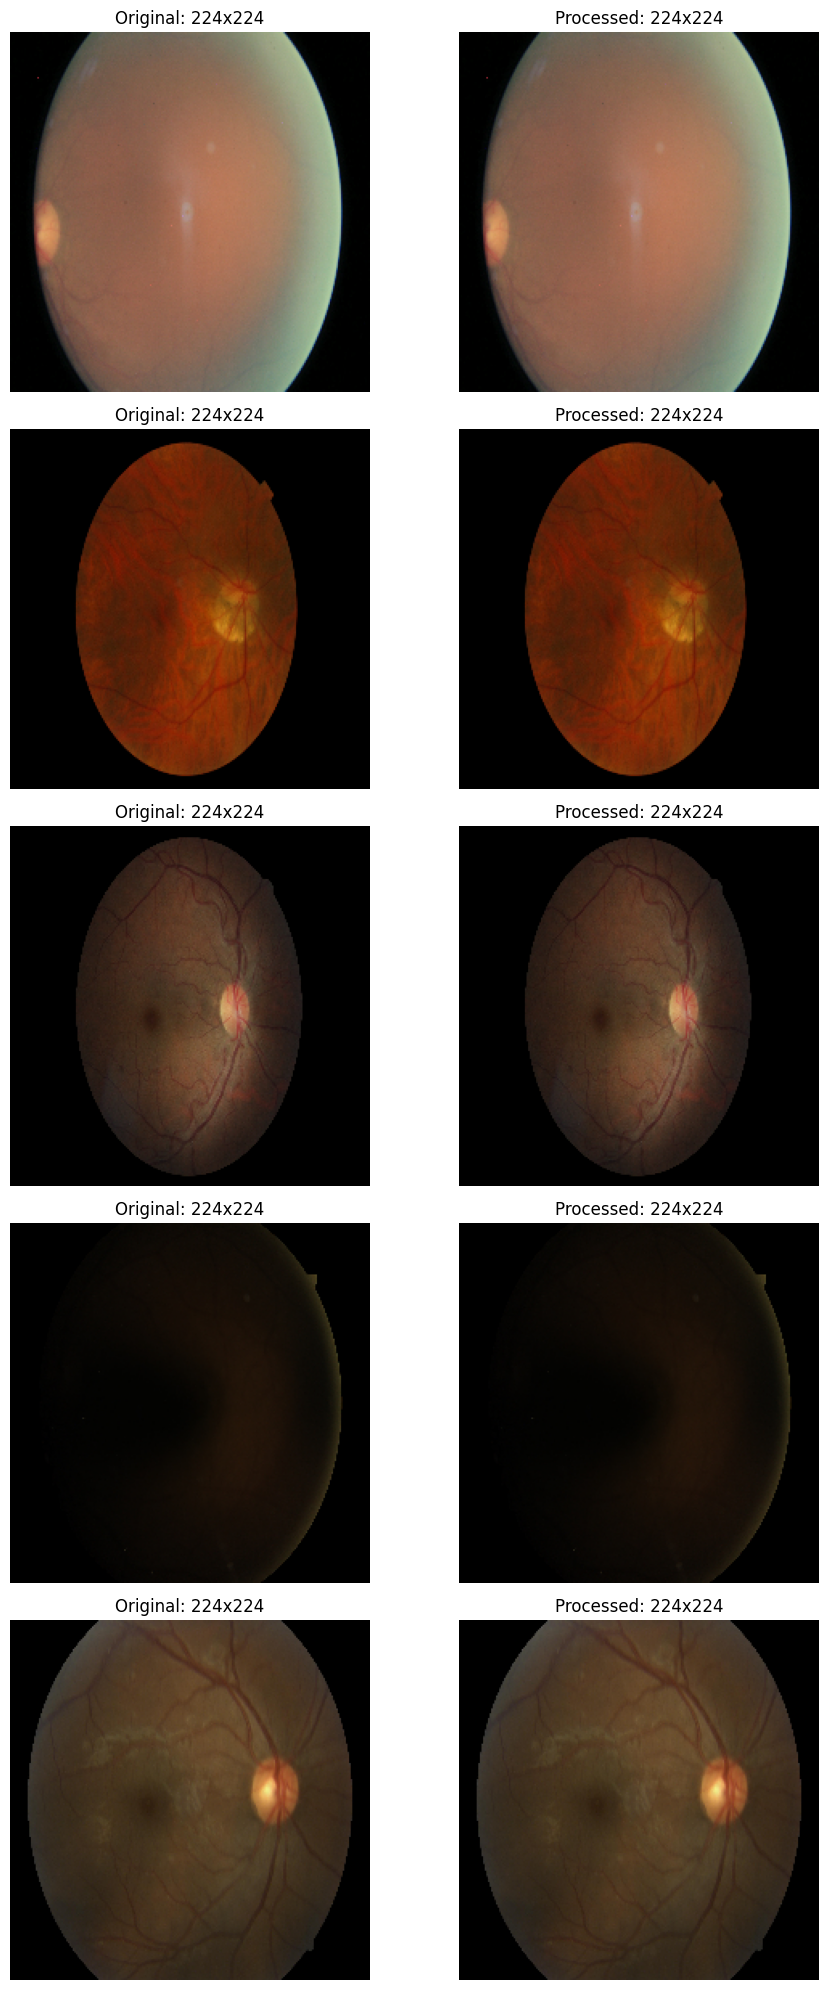

In [56]:
test_samples = valid_df.sample(
    n=min(5, len(valid_df)),
    random_state=SEED
)

fig, axes = plt.subplots(
    len(test_samples),
    2,
    figsize=(10, 4 * len(test_samples))
)

if len(test_samples) == 1:
    axes = np.array([axes])

for i, (_, row) in enumerate(
    test_samples.iterrows()
):

    original = cv2.imread(
        row["image_path"]
    )

    original = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    processed = resize_with_padding(
        original,
        IMG_SIZE
    )

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(
        f"Original: {original.shape[1]}x{original.shape[0]}"
    )

    axes[i, 1].imshow(processed)
    axes[i, 1].set_title(
        f"Processed: {IMG_SIZE}x{IMG_SIZE}"
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [57]:
prepared_records = []
failed_records = []

for idx, row in tqdm(
    valid_df.iterrows(),
    total=len(valid_df),
    desc="Preprocessing images"
):

    source_path = row["image_path"]
    label = row["level"]

    try:

        image = cv2.imread(source_path)

        if image is None:
            raise ValueError("Cannot read original image")

        processed = resize_with_padding(
            image,
            IMG_SIZE
        )

        output_name = f"image_{idx:06d}.jpg"

        output_path = os.path.join(
            IMAGE_DIR,
            output_name
        )

        success = cv2.imwrite(
            output_path,
            processed,
            [
                cv2.IMWRITE_JPEG_QUALITY,
                95
            ]
        )

        if not success:
            raise ValueError("Failed to save image")

        prepared_records.append({
            "image_path": output_path,
            "original_path": source_path,
            "level": label
        })

    except Exception as e:

        failed_records.append({
            "image_path": source_path,
            "level": label,
            "error": str(e)
        })

prepared_df = pd.DataFrame(
    prepared_records
)

failed_df = pd.DataFrame(
    failed_records
)

print("Successfully processed:", len(prepared_df))
print("Failed:", len(failed_df))

Preprocessing images:   0%|          | 0/35126 [00:00<?, ?it/s]

Successfully processed: 35126
Failed: 0


In [58]:
PREPARED_CSV = os.path.join(
    OUTPUT_DIR,
    "prepared_dataset.csv"
)

FAILED_CSV = os.path.join(
    OUTPUT_DIR,
    "failed_images.csv"
)

prepared_df.to_csv(
    PREPARED_CSV,
    index=False
)

failed_df.to_csv(
    FAILED_CSV,
    index=False
)

print("Prepared dataset saved.")
print("Failed images report saved.")

Prepared dataset saved.
Failed images report saved.


In [59]:
shape_errors = []
missing_processed = []

for _, row in tqdm(
    prepared_df.iterrows(),
    total=len(prepared_df),
    desc="Validating processed images"
):

    path = row["image_path"]

    if not os.path.exists(path):
        missing_processed.append(path)
        continue

    img = cv2.imread(path)

    if img is None:
        shape_errors.append({
            "image_path": path,
            "reason": "Unreadable processed image"
        })
        continue

    if img.shape != (224, 224, 3):
        shape_errors.append({
            "image_path": path,
            "reason": f"Unexpected shape: {img.shape}"
        })

print("Missing processed images:", len(missing_processed))
print("Invalid processed images:", len(shape_errors))

Validating processed images:   0%|          | 0/35126 [00:00<?, ?it/s]

Missing processed images: 0
Invalid processed images: 0


In [60]:
aspect_errors = []

for _, row in tqdm(
    dimensions_df.iterrows(),
    total=len(dimensions_df),
    desc="Checking aspect ratio"
):

    original_ratio = row["width"] / row["height"]

    scale = min(
        IMG_SIZE / row["width"],
        IMG_SIZE / row["height"]
    )

    resized_w = max(
        1,
        int(round(row["width"] * scale))
    )

    resized_h = max(
        1,
        int(round(row["height"] * scale))
    )

    processed_ratio = resized_w / resized_h

    relative_error = abs(
        original_ratio - processed_ratio
    ) / original_ratio

    if relative_error > 0.01:
        aspect_errors.append({
            "image_path": row["image_path"],
            "original_ratio": original_ratio,
            "processed_ratio": processed_ratio,
            "relative_error": relative_error
        })

print("Aspect ratio errors:", len(aspect_errors))

Checking aspect ratio:   0%|          | 0/35126 [00:00<?, ?it/s]

Aspect ratio errors: 0


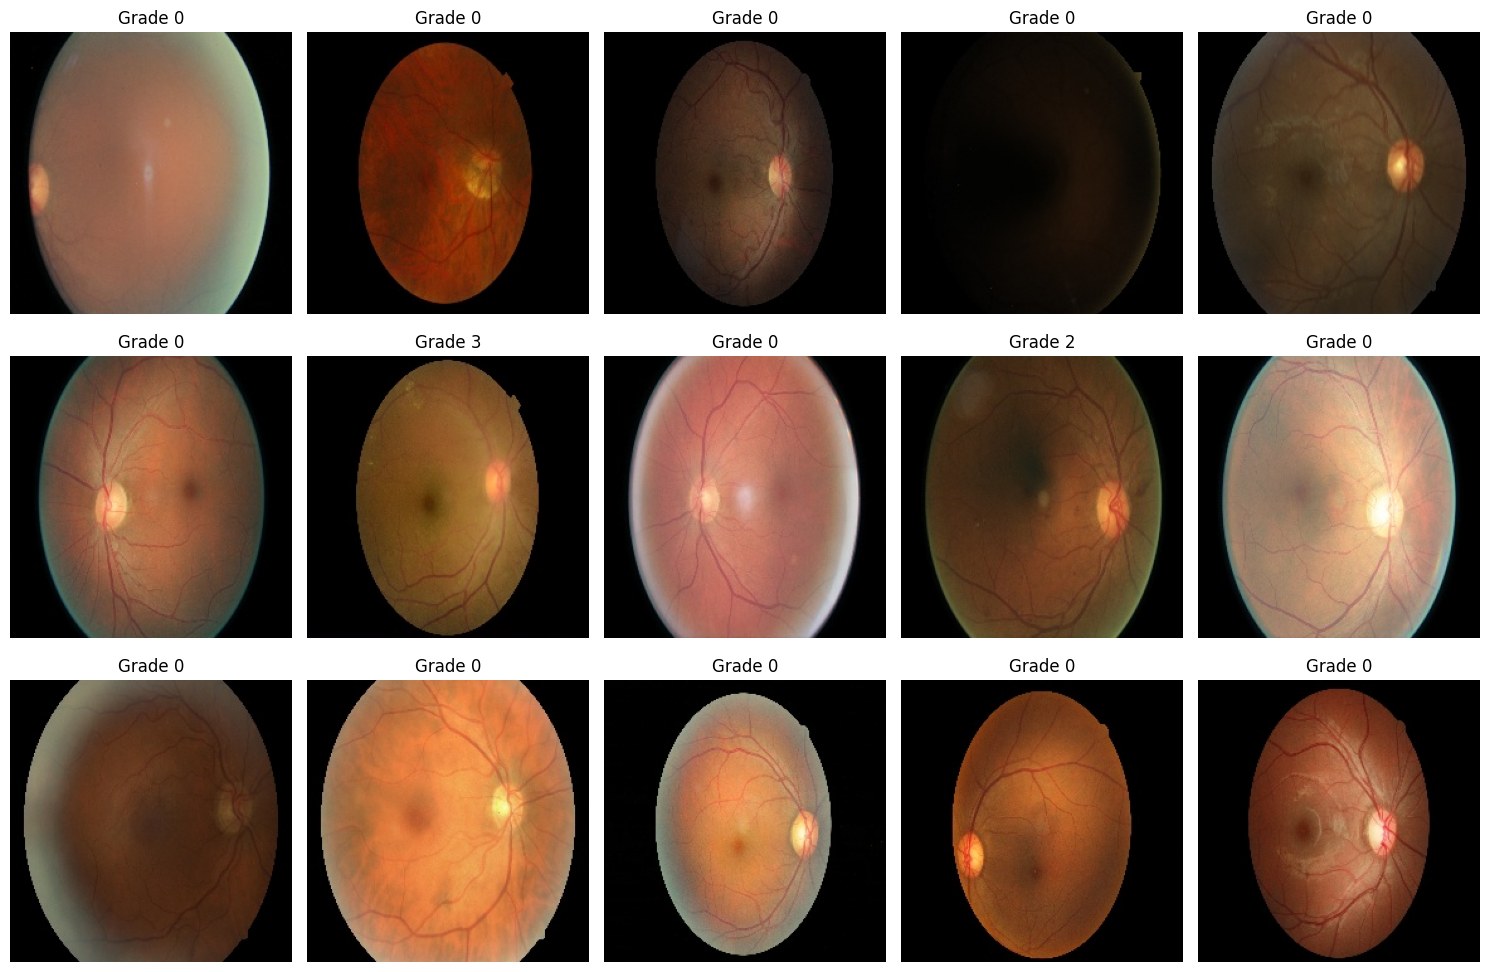

In [61]:
sample = prepared_df.sample(
    n=min(15, len(prepared_df)),
    random_state=SEED
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 10)
)

for ax, (_, row) in zip(
    axes.flat,
    sample.iterrows()
):

    img = cv2.imread(row["image_path"])

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(img)

    ax.set_title(
        f"Grade {row['level']}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [62]:
print("=" * 45)
print("PREPROCESSING SUMMARY")
print("=" * 45)

print("Original dataset:", len(df))
print("Valid original images:", len(valid_df))
print("Invalid original images:", len(invalid_df))

print("Successfully processed:", len(prepared_df))
print("Failed processing:", len(failed_df))

print("Missing processed:", len(missing_processed))
print("Invalid processed:", len(shape_errors))

print("Aspect ratio errors:", len(aspect_errors))

print("=" * 45)

PREPROCESSING SUMMARY
Original dataset: 35126
Valid original images: 35126
Invalid original images: 0
Successfully processed: 35126
Failed processing: 0
Missing processed: 0
Invalid processed: 0
Aspect ratio errors: 0


In [63]:
report = {
    "original_images": int(len(df)),
    "valid_original_images": int(len(valid_df)),
    "invalid_original_images": int(len(invalid_df)),
    "successfully_processed": int(len(prepared_df)),
    "failed_processing": int(len(failed_df)),
    "missing_processed": int(len(missing_processed)),
    "invalid_processed": int(len(shape_errors)),
    "aspect_ratio_errors": int(len(aspect_errors)),
    "target_size": IMG_SIZE
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "preprocessing_summary.json"
    ),
    "w"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print("Preprocessing report saved successfully.")

Preprocessing report saved successfully.
